In [3]:
import pandas as pd

df = pd.read_csv("../data/processed/matches.csv", parse_dates=["Date"])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4280 entries, 0 to 4279
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   Date      4280 non-null   datetime64[us]
 1   HomeTeam  4280 non-null   str           
 2   AwayTeam  4280 non-null   str           
 3   FTHG      4280 non-null   int64         
 4   FTAG      4280 non-null   int64         
 5   FTR       4280 non-null   str           
 6   season    4280 non-null   int64         
dtypes: datetime64[us](1), int64(3), str(3)
memory usage: 234.2 KB


In [4]:
(df.groupby("season")["FTR"]
   .value_counts(normalize=True)
   .unstack()
   .round(3))

FTR,A,D,H
season,,,
1516,0.305,0.282,0.413
1617,0.287,0.221,0.492
1718,0.284,0.261,0.455
1819,0.337,0.187,0.476
1920,0.305,0.242,0.453
2021,0.403,0.218,0.379
2122,0.339,0.232,0.429
2223,0.287,0.229,0.484
2324,0.324,0.216,0.461


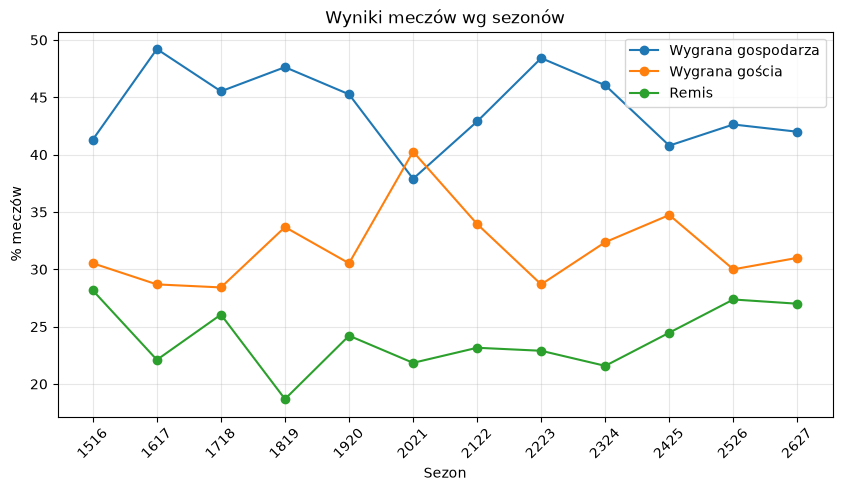

In [5]:
import matplotlib.pyplot as plt
from pathlib import Path

results = (df.groupby("season")["FTR"]
             .value_counts(normalize=True)
             .unstack())

# Zamiana sezonów na tekst wymusza na Matplotlib traktowanie ich jako osobne kategorie po kolei
sezony = results.index.astype(str)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(sezony, results["H"] * 100, marker="o", label="Wygrana gospodarza")
ax.plot(sezony, results["A"] * 100, marker="o", label="Wygrana gościa")
ax.plot(sezony, results["D"] * 100, marker="o", label="Remis")

ax.set_title("Wyniki meczów wg sezonów")
ax.set_xlabel("Sezon")
ax.set_ylabel("% meczów")

# Obrót etykiet na osi X o 45 stopni, aby były czytelne
ax.tick_params(axis="x", rotation=45)

ax.legend()
ax.grid(alpha=0.3)

Path("../reports/figures").mkdir(parents=True, exist_ok=True)
fig.savefig("../reports/figures/home_advantage.png", dpi=150, bbox_inches="tight")
plt.show()

## Wniosek: przewaga własnego boiska

Gospodarze wygrywają średnio ok. 44% meczów. W sezonie 2020/21,
granym bez kibiców, ten odsetek spadł do 37,9%, a goście wygrali
częściej niż gospodarze. Sugeruje to, że publiczność ma realny
wpływ na wynik.